# DECANT + PCA on the RNA pancreas dataset

DECANT feature selection (2,000 genes) followed by a PCA embedding on the pancreas scRNA-seq dataset, then evaluation with the six integration metrics and the Overall score.

Download the dataset from [Google Drive](https://drive.google.com/drive/folders/1gQBjm_2TH0Ozjg_jO_7rwSgeKNp8emVh?usp=sharing) and point `DATA_PATH` at it.

## Setup

In [1]:
import scanpy as sc
import pandas as pd
from decant.core import run_decant, run_pca
from decant.metrics import evaluate_metrics, calc_overall

DATA_PATH = "../data/pancreas.h5ad"   # edit to point at your file
OMICS = "rna"
BATCH_KEY = "tech"
LABEL_KEY = "celltype"
N_FEATURES = 2000
SEED = 0

## Data preprocessing

`adata.X` is log1p-normalised expression and is used as-is for feature ranking. Our example file is already log1p-normalised; if your data is raw counts, normalise it first:

```python
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
```

In [2]:
adata = sc.read_h5ad(DATA_PATH)
sc.pp.filter_genes(adata, min_cells=3)
adata

AnnData object with n_obs × n_vars = 16382 × 18268
    obs: 'tech', 'celltype', 'size_factors'
    var: 'n_cells'
    layers: 'counts'

## Visualize before DECANT (all features)

UMAP of a PCA embedding built from **all** preprocessed features, before DECANT selects any. Colour by batch and cell type, then compare with the after-DECANT UMAP.

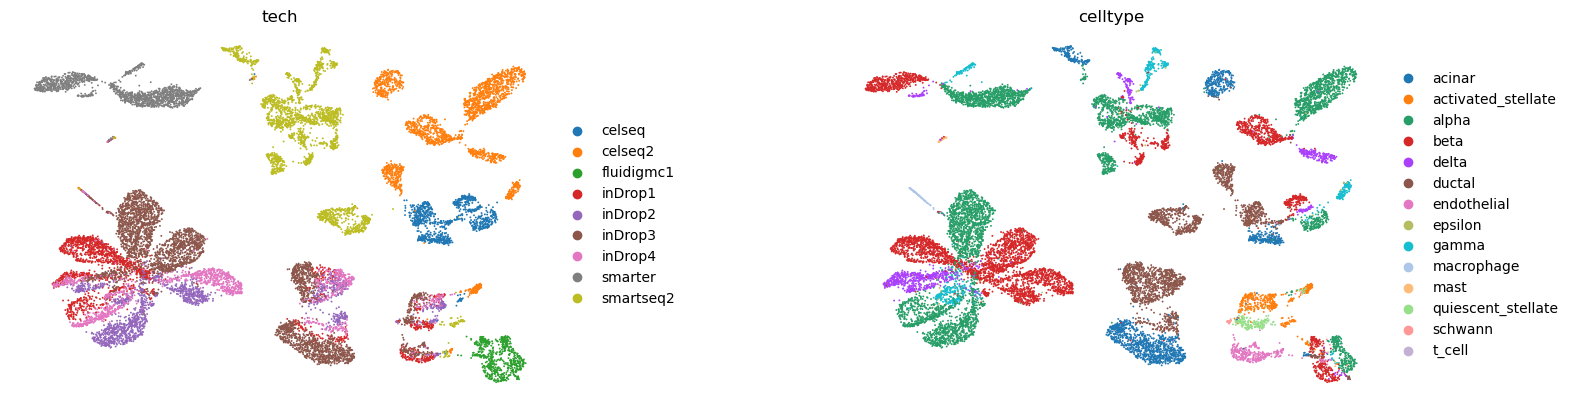

In [3]:
before, _ = run_pca(adata, OMICS, seed=SEED)
sc.pp.neighbors(before, use_rep="X_pca", n_neighbors=15, random_state=SEED)
sc.tl.umap(before, random_state=SEED)
sc.pl.umap(before, color=[BATCH_KEY, LABEL_KEY], wspace=0.4, frameon=False)


## DECANT feature selection

DECANT is label-free: it ranks features and selects the gamma with the highest tuning score.

In [4]:
result = run_decant(adata, omics=OMICS, batch_key=BATCH_KEY,
                    n_features=N_FEATURES, seed=SEED)
print(f"Selected {result['n_features']} features")


Selected 2000 features


The DECANT process is expected to take under 10 minutes.

## Evaluate integration

This step is downstream of feature selection: it benchmarks the DECANT embedding with the six integration metrics and the Overall score.

In [5]:
metrics = evaluate_metrics(result["embedding"], "X_pca", BATCH_KEY, LABEL_KEY)
metrics["Overall"] = calc_overall(metrics, result["n_batches"])
scores = pd.Series(metrics)
scores["iLISI"] = (metrics["iLISI"] - 1) / max(result["n_batches"] - 1, 1)
scores.round(4)


AMI                   0.7309
ARI                   0.5376
NMI                   0.7320
batchASW              0.8568
Graph_connectivity    0.9610
iLISI                 0.2696
Overall               0.6784
dtype: float64

## Visualize after DECANT (selected features)

UMAP of the DECANT embedding (PCA on the selected features). Same pipeline as the before-DECANT UMAP above, only the feature set differs.

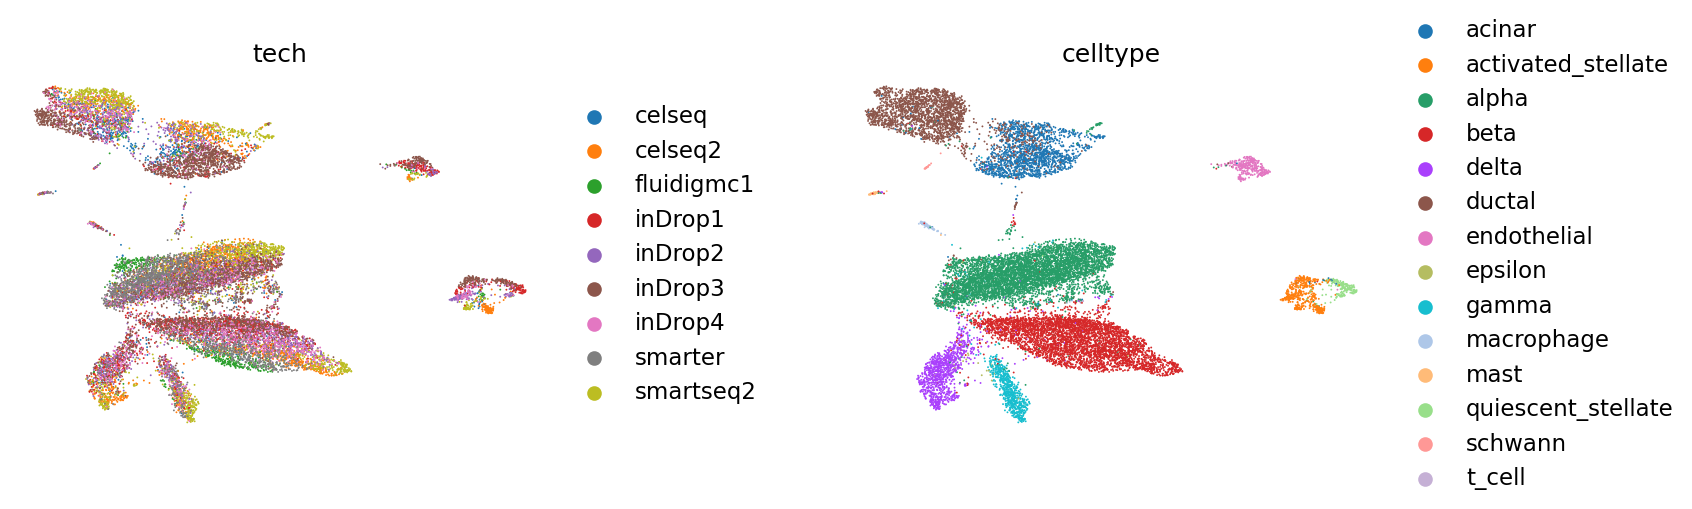

In [6]:
emb = result["embedding"]
sc.pp.neighbors(emb, use_rep="X_pca", n_neighbors=15, random_state=SEED)
sc.tl.umap(emb, random_state=SEED)
sc.pl.umap(emb, color=[BATCH_KEY, LABEL_KEY], wspace=0.4, frameon=False)
